# Análisis estadístico de ventas de BOSI y BAMBINO

**Descripción del proyecto**

Este proyecto tiene como objetivo analizar el comportamiento de las ventas de las marcas BOSI y BAMBINO durante las semanas 35 a 39 del año 2026, mediante técnicas de estadística descriptiva, visualización de datos y análisis comparativo.

Se utilizarán reportes reales de ventas y presupuestos comerciales, verificando la calidad y consistencia de la información antes de realizar los cálculos. Los resultados se presentarán de manera agregada para proteger la confidencialidad de la información empresarial.

In [1]:

# Importación de bibliotecas para el análisis de datos

import os
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Configuración para visualizar tablas completas
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

print("Bibliotecas importadas correctamente.")
print("Versión de Pandas:", pd.__version__)
print("Versión de NumPy:", np.__version__)


Bibliotecas importadas correctamente.
Versión de Pandas: 2.2.3
Versión de NumPy: 2.1.3


In [2]:

from google.colab import files

archivos_cargados = files.upload()

print("\nArchivos cargados:", len(archivos_cargados))

for nombre in archivos_cargados.keys():
    print("-", nombre)


Saving SEMANA 37 BAMBINO.txt to SEMANA 37 BAMBINO.txt
Saving SEMANA 39 BOSI.txt to SEMANA 39 BOSI.txt
Saving SEMANA 35 BOSI.txt to SEMANA 35 BOSI.txt
Saving SEMANA 36 BOSI.txt to SEMANA 36 BOSI.txt
Saving SEMANA 37 BOSI.txt to SEMANA 37 BOSI.txt
Saving SEMANA 38 BOSI.txt to SEMANA 38 BOSI.txt
Saving INFORME DE VENTA SEMANA 35.txt to INFORME DE VENTA SEMANA 35.txt
Saving INFORME DE VENTA SEMANA 36.txt to INFORME DE VENTA SEMANA 36.txt
Saving INFORME DE VENTA SEMANA 37.txt to INFORME DE VENTA SEMANA 37.txt
Saving INFORME DE VENTA SEMANA 38.txt to INFORME DE VENTA SEMANA 38.txt
Saving INFORME DE VENTA SEMANA 39.txt to INFORME DE VENTA SEMANA 39.txt
Saving SEMANA 35 BAMBINO.txt to SEMANA 35 BAMBINO.txt
Saving SEMANA 36 BAMBINO.txt to SEMANA 36 BAMBINO.txt
Saving SEMANA 38 BAMBINO.txt to SEMANA 38 BAMBINO.txt
Saving SEMANA 39 BAMBINO.txt to SEMANA 39 BAMBINO.txt

Archivos cargados: 15
- SEMANA 37 BAMBINO.txt
- SEMANA 39 BOSI.txt
- SEMANA 35 BOSI.txt
- SEMANA 36 BOSI.txt
- SEMANA 37 BOSI.txt

In [3]:

# Verificación de los archivos de presupuesto

for semana in range(35, 40):
    for marca in ["BOSI", "BAMBINO"]:
        nombre = f"SEMANA {semana} {marca}.txt"

        print("\n" + "=" * 60)
        print(f"ARCHIVO: {nombre}")
        print("=" * 60)

        with open(nombre, "r", encoding="utf-8", errors="replace") as archivo:
            lineas = archivo.readlines()

        # Mostrar las primeras líneas para comprobar la marca y el presupuesto
        for linea in lineas[:15]:
            print(linea.rstrip())



ARCHIVO: SEMANA 35 BOSI.txt
EMPRESA  :COMERCIALIZADORA BALDINI S.A. A�O    : 2026
INFORME  :MINIMOS SEMANALES             SEMANA : 35 (30/08/2026 al 5/09/2026)
FECHA    :VIE, OCT 09 de 2026           NEGOCIO: BOSI
HORA     :04:32:32 Pag :0001            MINIMO : 15,895,000
                                        META   : 18,700,000
-----------------------------------------------------------------------------------------------------------------------------------
                           |     DOM    |     LUN    |     MAR    |     MIE    |     JUE    |     VIE    |     SAB    |     TOT    |
                           |    27.80   |     8.97   |     9.00   |     9.81   |    10.80   |    13.80   |    19.82   |
                           |  4,418,810 |  1,425,782 |  1,430,550 |  1,559,300 |  1,716,660 |  2,193,510 |  3,150,389 |
                           |  5,198,600 |  1,677,390 |  1,683,000 |  1,834,470 |  2,019,600 |  2,580,600 |  3,706,340 |
--------------------------------------

In [4]:

# Extracción automática de presupuestos por semana y marca

import os
import re
import pandas as pd

presupuestos = []

for semana in range(35, 40):
    for marca in ["BOSI", "BAMBINO"]:
        nombre = f"SEMANA {semana} {marca}.txt"

        with open(nombre, "r", encoding="latin-1", errors="replace") as archivo:
            contenido = archivo.read()

        negocio = re.search(r"NEGOCIO:\s*(BOSI|BAMBINO)", contenido)
        minimo = re.search(r"MINIMO\s*:\s*([\d,]+)", contenido)
        meta = re.search(r"META\s*:\s*([\d,]+)", contenido)

        if negocio and minimo and meta:
            marca_archivo = negocio.group(1).strip()

            presupuestos.append({
                "Semana": semana,
                "Marca_archivo": marca_archivo,
                "Marca_esperada": marca,
                "Mínimo": int(minimo.group(1).replace(",", "")),
                "Meta": int(meta.group(1).replace(",", "")),
                "Archivo": nombre
            })
        else:
            print(f"⚠️ No se pudieron extraer todos los datos de {nombre}")

df_presupuestos = pd.DataFrame(presupuestos)

# Verificar que la marca del contenido coincida con el nombre del archivo
df_presupuestos["Marca_correcta"] = (
    df_presupuestos["Marca_archivo"] == df_presupuestos["Marca_esperada"]
)

display(df_presupuestos)

if df_presupuestos["Marca_correcta"].all() and len(df_presupuestos) == 10:
    print("✅ Verificación correcta: 10 presupuestos identificados.")
else:
    print("⚠️ Atención: revisa los archivos que aparecen con diferencias.")


,Semana,Marca_archivo,Marca_esperada,Mínimo,Meta,Archivo,Marca_correcta
0,35,BOSI,BOSI,15895000,18700000,SEMANA 35 BOSI.txt,True
1,35,BAMBINO,BAMBINO,4029000,4740000,SEMANA 35 BAMBINO.txt,True
2,36,BOSI,BOSI,11050000,13000000,SEMANA 36 BOSI.txt,True
3,36,BAMBINO,BAMBINO,2524500,2970000,SEMANA 36 BAMBINO.txt,True
4,37,BOSI,BOSI,15436000,18160000,SEMANA 37 BOSI.txt,True
5,37,BAMBINO,BAMBINO,2626500,3090000,SEMANA 37 BAMBINO.txt,True
6,38,BOSI,BOSI,22695000,26700000,SEMANA 38 BOSI.txt,True
7,38,BAMBINO,BAMBINO,2898500,3410000,SEMANA 38 BAMBINO.txt,True
8,39,BOSI,BOSI,10854500,12770000,SEMANA 39 BOSI.txt,True
9,39,BAMBINO,BAMBINO,2456500,2890000,SEMANA 39 BAMBINO.txt,True


✅ Verificación correcta: 10 presupuestos identificados.


In [5]:

# Extracción de ventas reales de los informes semanales

import re
import pandas as pd

ventas = []

for semana in range(35, 40):
    nombre = f"INFORME DE VENTA SEMANA {semana}.txt"

    with open(nombre, "r", encoding="latin-1", errors="replace") as archivo:
        contenido = archivo.read()

    # Buscar los totales de cada marca dentro del informe
    for marca in ["BOSI", "BAMBINO"]:
        # Mostrar fragmentos que contengan el nombre de la marca
        coincidencias = [
            linea for linea in contenido.splitlines()
            if marca in linea.upper()
        ]

        print(f"\nSemana {semana} - {marca}")
        for linea in coincidencias[:5]:
            print(linea)



Semana 35 - BOSI
.                                 Venta BOSI               84     42  20,191,465.00
.                                 - NC Bosi                              741,268.00
.                                 Subtotal BOSI                       19,450,197.00
.                                 Venta BOSI               11      3   2,222,655.00
.                                 - NC Bosi                              138,713.00

Semana 35 - BAMBINO
.                                 Venta BAMBINO            26     22   4,337,405.00
.                                 - NC Bambino                           179,901.00
.                                 Subtotal BAMBINO                     4,157,504.00
.                                 Particip. Bambino                           17.61
.                                 Venta BAMBINO             4      3     567,225.00

Semana 36 - BOSI
.                                 Venta BOSI               59     27  15,716,800.00
.                  

In [6]:

# Registro de ventas netas generales verificadas por semana y marca

ventas_reales = [
    {"Semana": 35, "Marca": "BOSI",    "Venta_neta": 19450197},
    {"Semana": 36, "Marca": "BOSI",    "Venta_neta": 15304950},
    {"Semana": 37, "Marca": "BOSI",    "Venta_neta": 17148505},
    {"Semana": 38, "Marca": "BOSI",    "Venta_neta": 19999694},
    {"Semana": 39, "Marca": "BOSI",    "Venta_neta": 12226700},
    {"Semana": 35, "Marca": "BAMBINO", "Venta_neta": 4157504},
    {"Semana": 36, "Marca": "BAMBINO", "Venta_neta": 3333415},
    {"Semana": 37, "Marca": "BAMBINO", "Venta_neta": 2596125},
    {"Semana": 38, "Marca": "BAMBINO", "Venta_neta": 3344065},
    {"Semana": 39, "Marca": "BAMBINO", "Venta_neta": 3139350},
]

df_ventas = pd.DataFrame(ventas_reales)

# Unir las ventas reales con los presupuestos verificados
df_presupuestos_limpio = df_presupuestos[
    ["Semana", "Marca_esperada", "Mínimo", "Meta", "Marca_correcta"]
].rename(columns={"Marca_esperada": "Marca"})

df_analisis = pd.merge(
    df_ventas,
    df_presupuestos_limpio,
    on=["Semana", "Marca"],
    how="left",
    validate="one_to_one"
)

# Calcular indicadores comerciales
df_analisis["Cumplimiento_meta_%"] = (
    df_analisis["Venta_neta"] / df_analisis["Meta"] * 100
).round(2)

df_analisis["Cumplimiento_minimo_%"] = (
    df_analisis["Venta_neta"] / df_analisis["Mínimo"] * 100
).round(2)

df_analisis["Diferencia_meta"] = (
    df_analisis["Venta_neta"] - df_analisis["Meta"]
)

df_analisis["Diferencia_minimo"] = (
    df_analisis["Venta_neta"] - df_analisis["Mínimo"]
)

# Ordenar la tabla
df_analisis = df_analisis.sort_values(
    ["Semana", "Marca"]
).reset_index(drop=True)

display(df_analisis)

print("Número de registros:", len(df_analisis))
print("¿Hay datos faltantes?")
display(df_analisis.isnull().sum())


,Semana,Marca,Venta_neta,Mínimo,Meta,Marca_correcta,Cumplimiento_meta_%,Cumplimiento_minimo_%,Diferencia_meta,Diferencia_minimo
0,35,BAMBINO,4157504,4029000,4740000,True,87.71,103.19,-582496,128504
1,35,BOSI,19450197,15895000,18700000,True,104.01,122.37,750197,3555197
2,36,BAMBINO,3333415,2524500,2970000,True,112.24,132.04,363415,808915
3,36,BOSI,15304950,11050000,13000000,True,117.73,138.51,2304950,4254950
4,37,BAMBINO,2596125,2626500,3090000,True,84.02,98.84,-493875,-30375
5,37,BOSI,17148505,15436000,18160000,True,94.43,111.09,-1011495,1712505
6,38,BAMBINO,3344065,2898500,3410000,True,98.07,115.37,-65935,445565
7,38,BOSI,19999694,22695000,26700000,True,74.91,88.12,-6700306,-2695306
8,39,BAMBINO,3139350,2456500,2890000,True,108.63,127.80,249350,682850
9,39,BOSI,12226700,10854500,12770000,True,95.75,112.64,-543300,1372200


Número de registros: 10
¿Hay datos faltantes?


,0
Semana,0
Marca,0
Venta_neta,0
Mínimo,0
Meta,0
Marca_correcta,0
Cumplimiento_meta_%,0
Cumplimiento_minimo_%,0
Diferencia_meta,0
Diferencia_minimo,0


In [7]:

# Estadística descriptiva de las ventas y el cumplimiento

estadisticas = df_analisis.groupby("Marca").agg(
    Semanas_analizadas=("Semana", "count"),
    Venta_promedio=("Venta_neta", "mean"),
    Venta_mediana=("Venta_neta", "median"),
    Venta_minima=("Venta_neta", "min"),
    Venta_maxima=("Venta_neta", "max"),
    Desviacion_estandar=("Venta_neta", "std"),
    Cumplimiento_promedio_meta=("Cumplimiento_meta_%", "mean"),
    Cumplimiento_promedio_minimo=("Cumplimiento_minimo_%", "mean")
).round(2)

display(estadisticas)

# Resumen de ventas por semana
print("Ventas netas por semana y marca:")

tabla_ventas = df_analisis.pivot(
    index="Semana",
    columns="Marca",
    values="Venta_neta"
)

display(tabla_ventas)


,Semanas_analizadas,Venta_promedio,Venta_mediana,Venta_minima,Venta_maxima,Desviacion_estandar,Cumplimiento_promedio_meta,Cumplimiento_promedio_minimo
Marca,,,,,,,,
BAMBINO,5,3314091.8,3333415.0,2596125,4157504,560942.72,98.13,115.45
BOSI,5,16826009.2,17148505.0,12226700,19999694,3183155.14,97.37,114.55


Ventas netas por semana y marca:


Marca,BAMBINO,BOSI
Semana,,
35,4157504,19450197
36,3333415,15304950
37,2596125,17148505
38,3344065,19999694
39,3139350,12226700


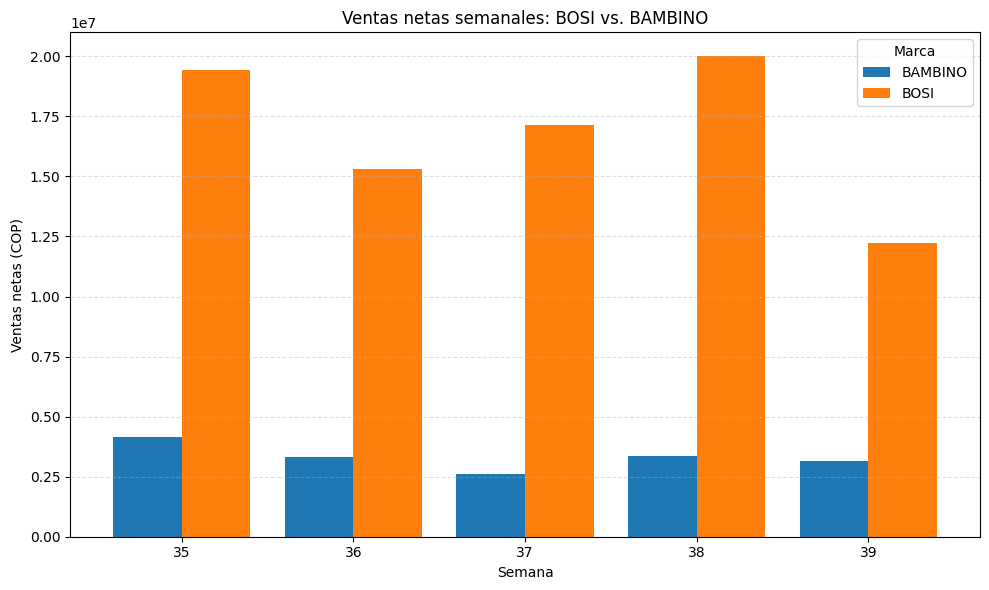

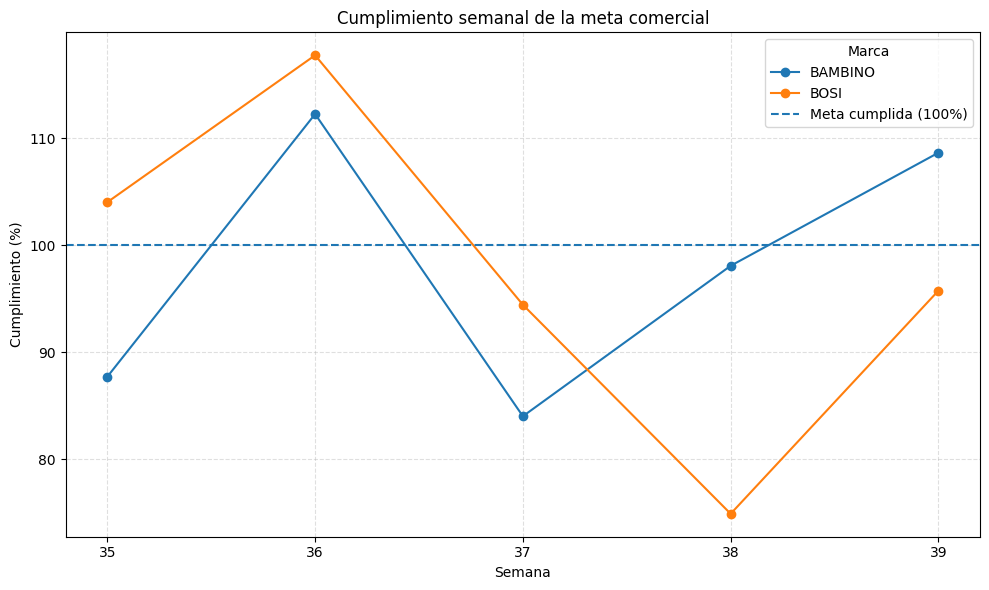

In [8]:

# Gráfica 1. Comparación de ventas netas semanales

tabla_ventas.plot(
    kind="bar",
    figsize=(10, 6),
    width=0.8
)

plt.title("Ventas netas semanales: BOSI vs. BAMBINO")
plt.xlabel("Semana")
plt.ylabel("Ventas netas (COP)")
plt.xticks(rotation=0)
plt.legend(title="Marca")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

# Gráfica 2. Cumplimiento semanal de la meta

tabla_cumplimiento = df_analisis.pivot(
    index="Semana",
    columns="Marca",
    values="Cumplimiento_meta_%"
)

tabla_cumplimiento.plot(
    kind="line",
    marker="o",
    figsize=(10, 6)
)

plt.axhline(
    y=100,
    linestyle="--",
    label="Meta cumplida (100%)"
)

plt.title("Cumplimiento semanal de la meta comercial")
plt.xlabel("Semana")
plt.ylabel("Cumplimiento (%)")
plt.xticks([35, 36, 37, 38, 39])
plt.legend(title="Marca")
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


In [9]:

# Paso 10. Análisis de variabilidad y cumplimiento comercial

resumen_variabilidad = df_analisis.groupby("Marca").agg(
    Promedio_ventas=("Venta_neta", "mean"),
    Desviacion_estandar=("Venta_neta", "std"),
    Cumplimiento_promedio_meta=("Cumplimiento_meta_%", "mean"),
    Semanas_cumple_meta=(
        "Cumplimiento_meta_%",
        lambda x: (x >= 100).sum()
    ),
    Semanas_cumple_minimo=(
        "Cumplimiento_minimo_%",
        lambda x: (x >= 100).sum()
    )
)

# Coeficiente de variación: variabilidad relativa de las ventas
resumen_variabilidad["Coeficiente_variacion_%"] = (
    resumen_variabilidad["Desviacion_estandar"]
    / resumen_variabilidad["Promedio_ventas"] * 100
).round(2)

resumen_variabilidad = resumen_variabilidad.round(2)

display(resumen_variabilidad)

# Identificar la mejor y la peor semana de cada marca
for marca in ["BOSI", "BAMBINO"]:
    datos_marca = df_analisis[df_analisis["Marca"] == marca]

    mejor = datos_marca.loc[datos_marca["Venta_neta"].idxmax()]
    peor = datos_marca.loc[datos_marca["Venta_neta"].idxmin()]

    print(f"\n{marca}")
    print(
        f"Mayor venta: semana {int(mejor['Semana'])}, "
        f"${mejor['Venta_neta']:,.0f}"
    )
    print(
        f"Menor venta: semana {int(peor['Semana'])}, "
        f"${peor['Venta_neta']:,.0f}"
    )


,Promedio_ventas,Desviacion_estandar,Cumplimiento_promedio_meta,Semanas_cumple_meta,Semanas_cumple_minimo,Coeficiente_variacion_%
Marca,,,,,,
BAMBINO,3314091.8,560942.72,98.13,2,4,16.93
BOSI,16826009.2,3183155.14,97.37,2,4,18.92



BOSI
Mayor venta: semana 38, $19,999,694
Menor venta: semana 39, $12,226,700

BAMBINO
Mayor venta: semana 35, $4,157,504
Menor venta: semana 37, $2,596,125


In [10]:

# PASO 11. Conclusiones del análisis comercial

print("CONCLUSIONES DEL ANÁLISIS COMERCIAL")
print("=" * 45)

for marca in ["BOSI", "BAMBINO"]:
    datos = df_analisis[df_analisis["Marca"] == marca]

    promedio_ventas = datos["Venta_neta"].mean()
    cumplimiento_meta = datos["Cumplimiento_meta_%"].mean()
    cumplimiento_minimo = datos["Cumplimiento_minimo_%"].mean()

    semanas_meta = (datos["Cumplimiento_meta_%"] >= 100).sum()
    semanas_minimo = (datos["Cumplimiento_minimo_%"] >= 100).sum()

    mejor = datos.loc[datos["Venta_neta"].idxmax()]
    peor = datos.loc[datos["Venta_neta"].idxmin()]

    print(f"\nMarca: {marca}")
    print(f"Promedio de ventas: ${promedio_ventas:,.0f}")
    print(f"Cumplimiento promedio de la meta: {cumplimiento_meta:.2f}%")
    print(f"Cumplimiento promedio del mínimo: {cumplimiento_minimo:.2f}%")
    print(f"Semanas que cumplieron la meta: {semanas_meta} de 5")
    print(f"Semanas que cumplieron el mínimo: {semanas_minimo} de 5")
    print(f"Mejor semana: {int(mejor['Semana'])}")
    print(f"Semana de menor venta: {int(peor['Semana'])}")


CONCLUSIONES DEL ANÁLISIS COMERCIAL

Marca: BOSI
Promedio de ventas: $16,826,009
Cumplimiento promedio de la meta: 97.37%
Cumplimiento promedio del mínimo: 114.55%
Semanas que cumplieron la meta: 2 de 5
Semanas que cumplieron el mínimo: 4 de 5
Mejor semana: 38
Semana de menor venta: 39

Marca: BAMBINO
Promedio de ventas: $3,314,092
Cumplimiento promedio de la meta: 98.13%
Cumplimiento promedio del mínimo: 115.45%
Semanas que cumplieron la meta: 2 de 5
Semanas que cumplieron el mínimo: 4 de 5
Mejor semana: 35
Semana de menor venta: 37


In [11]:

# PASO 12. Tabla resumen final por marca

tabla_resumen = df_analisis.groupby("Marca").agg(
    Promedio_ventas=("Venta_neta", "mean"),
    Promedio_meta=("Meta", "mean"),
    Promedio_minimo=("Mínimo", "mean"),
    Cumplimiento_meta=("Cumplimiento_meta_%", "mean"),
    Cumplimiento_minimo=("Cumplimiento_minimo_%", "mean"),
    Semanas_analizadas=("Semana", "nunique")
).round(2)

display(tabla_resumen)

# Verificar la calidad de los datos
print("\nCONTROL DE CALIDAD")
print("Total de registros:", len(df_analisis))
print("Valores faltantes:", df_analisis.isnull().sum().sum())
print("Marcas analizadas:", df_analisis["Marca"].nunique())
print("Semanas analizadas:", df_analisis["Semana"].nunique())


,Promedio_ventas,Promedio_meta,Promedio_minimo,Cumplimiento_meta,Cumplimiento_minimo,Semanas_analizadas
Marca,,,,,,
BAMBINO,3314091.8,3420000.0,2907000.0,98.13,115.45,5
BOSI,16826009.2,17866000.0,15186100.0,97.37,114.55,5



CONTROL DE CALIDAD
Total de registros: 10
Valores faltantes: 0
Marcas analizadas: 2
Semanas analizadas: 5


In [14]:

# PASO 13. Exportar los resultados del análisis

nombre_archivo = "analisis_comercial_semanas_35_39.csv"

df_analisis.to_csv(
    nombre_archivo,
    index=False,
    encoding="utf-8-sig"
)

print(f"Archivo generado correctamente: {nombre_archivo}")

# Descargar el archivo a tu computador
from google.colab import files
files.download(nombre_archivo)


Archivo generado correctamente: analisis_comercial_semanas_35_39.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<Figure size 900x600 with 0 Axes>

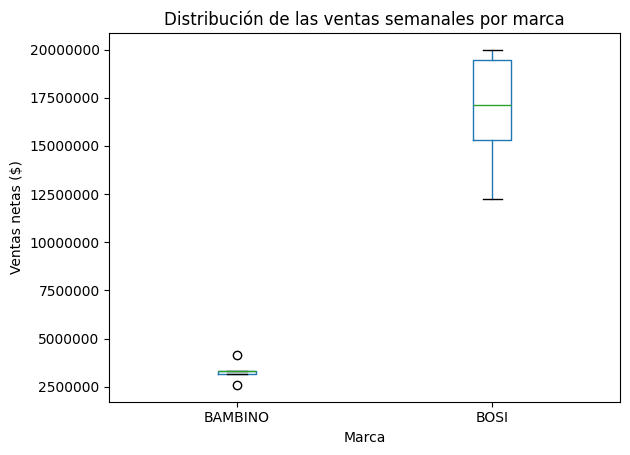

In [12]:

# PASO 14. Diagrama de caja de las ventas semanales

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))

df_analisis.boxplot(
    column="Venta_neta",
    by="Marca",
    grid=False
)

plt.title("Distribución de las ventas semanales por marca")
plt.suptitle("")
plt.xlabel("Marca")
plt.ylabel("Ventas netas ($)")
plt.ticklabel_format(style="plain", axis="y")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [13]:

# PASO 15. Comparación estadística exploratoria entre marcas

from scipy.stats import wilcoxon

# Organizar las ventas de ambas marcas por semana
comparacion = df_analisis.pivot(
    index="Semana",
    columns="Marca",
    values="Venta_neta"
).sort_index()

display(comparacion)

# Diferencia semanal entre las ventas de BOSI y BAMBINO
diferencias = comparacion["BOSI"] - comparacion["BAMBINO"]

print("\nDiferencias semanales (BOSI - BAMBINO):")
display(diferencias.to_frame("Diferencia_ventas"))

# Prueba de Wilcoxon para datos relacionados
resultado = wilcoxon(
    comparacion["BOSI"],
    comparacion["BAMBINO"],
    alternative="two-sided"
)

print("\nRESULTADO DE LA PRUEBA DE WILCOXON")
print(f"Estadístico: {resultado.statistic}")
print(f"Valor p: {resultado.pvalue:.4f}")

if resultado.pvalue < 0.05:
    print("El resultado es estadísticamente significativo al nivel del 5%.")
else:
    print("No se encontró evidencia estadística suficiente de una diferencia al nivel del 5%.")

print(
    "\nPrecaución: solo se analizaron cinco semanas. "
    "El resultado es exploratorio y no demuestra causalidad."
)


Marca,BAMBINO,BOSI
Semana,,
35,4157504,19450197
36,3333415,15304950
37,2596125,17148505
38,3344065,19999694
39,3139350,12226700



Diferencias semanales (BOSI - BAMBINO):


,Diferencia_ventas
Semana,
35,15292693
36,11971535
37,14552380
38,16655629
39,9087350



RESULTADO DE LA PRUEBA DE WILCOXON
Estadístico: 0.0
Valor p: 0.0625
No se encontró evidencia estadística suficiente de una diferencia al nivel del 5%.

Precaución: solo se analizaron cinco semanas. El resultado es exploratorio y no demuestra causalidad.


**Paso 16. Interpretar el resultado de Wilcoxon**

El resultado fue:

*   Estadístico de Wilcoxon	0,0
*   Valor p	0,0625
*   Nivel de significancia	0,05
*   Nivel de significancia	0,05
*   Conclusión	No significativo al 5 %

¿Qué significa?
El valor p de 0,0625 es superior al nivel de significancia de 0,05. Por tanto, no encontramos evidencia estadística suficiente para rechazar la hipótesis nula con esta prueba.
Esto no significa que las ventas de ambas marcas sean iguales. En las cinco semanas observadas, BOSI tuvo ventas superiores a BAMBINO, pero solo contamos con cinco pares de observaciones. Por eso, el resultado debe interpretarse con cautela.
Además, el valor p de 0,0625 es coherente con una prueba exacta bilateral de Wilcoxon cuando las cinco diferencias tienen el mismo signo. La muestra es demasiado pequeña para obtener conclusiones generales sólidas.

In [15]:

# PASO 17. Correlación exploratoria entre las ventas de las marcas

from scipy.stats import spearmanr

correlacion, valor_p = spearmanr(
    comparacion["BOSI"],
    comparacion["BAMBINO"]
)

print("ANÁLISIS DE CORRELACIÓN DE SPEARMAN")
print(f"Coeficiente de correlación: {correlacion:.3f}")
print(f"Valor p: {valor_p:.4f}")

if correlacion > 0:
    print("La asociación observada es positiva.")
elif correlacion < 0:
    print("La asociación observada es negativa.")
else:
    print("No se observa asociación monotónica.")

print(
    "\nInterpretación: el resultado es exploratorio, "
    "porque solo se dispone de cinco semanas."
)


ANÁLISIS DE CORRELACIÓN DE SPEARMAN
Coeficiente de correlación: 0.600
Valor p: 0.2848
La asociación observada es positiva.

Interpretación: el resultado es exploratorio, porque solo se dispone de cinco semanas.


**Paso 18. Interpretación de la correlación**

*   Coeficiente de Spearman	0,600
*   Valor p	0,2848
*   Nivel de significancia	0,05

Interpretación: se observa una asociación positiva entre las ventas de ambas marcas. Esto significa que, en las semanas analizadas, existe cierta tendencia a que ambas marcas se ubiquen en posiciones similares de ventas relativas. Sin embargo, el valor p de 0,2848 supera el nivel de significancia de 0,05, por lo que no hay evidencia estadística suficiente para afirmar que exista una asociación monotónica en la población.

In [16]:

# PASO 19. Verificación final del conjunto de datos

print("REVISIÓN FINAL DEL NOTEBOOK")
print("=" * 40)

print(f"Registros analizados: {len(df_analisis)}")
print(f"Marcas: {sorted(df_analisis['Marca'].unique())}")
print(f"Semanas: {sorted(df_analisis['Semana'].unique())}")
print(f"Valores faltantes: {df_analisis.isnull().sum().sum()}")

print("\nColumnas disponibles:")
print(df_analisis.columns.tolist())

# Comprobar que las ventas sean positivas
print(
    "\n¿Todas las ventas son positivas?:",
    (df_analisis["Venta_neta"] > 0).all()
)

# Comprobar que cada semana tenga las dos marcas
marcas_por_semana = df_analisis.groupby("Semana")["Marca"].nunique()
print(
    "¿Cada semana tiene las dos marcas?:",
    (marcas_por_semana == 2).all()
)


REVISIÓN FINAL DEL NOTEBOOK
Registros analizados: 10
Marcas: ['BAMBINO', 'BOSI']
Semanas: [np.int64(35), np.int64(36), np.int64(37), np.int64(38), np.int64(39)]
Valores faltantes: 0

Columnas disponibles:
['Semana', 'Marca', 'Venta_neta', 'Mínimo', 'Meta', 'Marca_correcta', 'Cumplimiento_meta_%', 'Cumplimiento_minimo_%', 'Diferencia_meta', 'Diferencia_minimo']

¿Todas las ventas son positivas?: True
¿Cada semana tiene las dos marcas?: True
